# Olist 이커머스 고객 분석

브라질 이커머스 마켓플레이스 Olist의 주문 데이터(2016-09 ~ 2018-10, 주문 99,441건)를 DuckDB에 적재하고 SQL로 고객의 재구매 구조를 분석했습니다. 배송 지연이 고객 경험과 재구매에 미친 영향은 통제 변수를 넣은 로지스틱 회귀로 확인했습니다.

**분석 질문**
1. 이 서비스의 고객은 실제로 다시 구매하는가, 다시 구매한다면 언제인가
2. 매출은 어떤 고객에게 몰려 있는가
3. 어떤 카테고리로 시작한 고객이 다시 돌아왔고, 두 번째 구매는 어디로 이어졌는가
4. 배송 지연은 리뷰와 재구매를 얼마나 떨어뜨렸는가

**주요 결과**
- 같은 날 나뉜 주문을 제외한 실제 재구매 고객은 2.15%였고, 1년 안에 두 번째 구매를 한 고객도 3.33%에 그쳤습니다. 재구매에 기대는 성장 전략은 맞지 않는 구조로 판단했습니다.
- 구매액 상위 20% 고객이 매출의 53.5%를 차지했습니다.
- 첫 주문이 예정일보다 늦게 도착하면 낮은 리뷰(1~2점) 비율이 9.5%에서 65.4%로 올랐습니다. 금액, 지역, 카테고리, 구매 월을 통제한 뒤에도 낮은 리뷰 확률이 평균 26.3%p 높았습니다.
- 반면 배송 지연이 180일 내 재구매를 낮췄다는 근거는 통계적으로 확인되지 않았습니다(p = 0.18).
- 지연 비율은 2017-11(12.4%), 2018-02(14.1%), 2018-03(19.0%)에 급등했습니다. 지연이 급증한 시기의 배송 관리가 고객 경험 지표에 가장 직접적인 영향을 준 것으로 판단했습니다.
- 이 결과를 검증하기 위해 지연 급증 시기에 배송 예정일을 더 길게 안내하는 A/B 테스트를 설계했습니다. 낮은 리뷰 2%p 감소를 확인하려면 그룹당 약 6,000명, 약 2개월이 필요하다는 점을 계산했습니다.

| 단계 | 내용 | 주로 사용한 SQL |
|---|---|---|
| 1 | 데이터 구조와 분석 기준 확인 | GROUP BY, CASE, 윈도우 함수(비율) |
| 2 | 분석용 테이블 생성 | CTE, JOIN, ROW_NUMBER |
| 3 | 코호트 재구매 분석 | DATE_TRUNC, DATE_DIFF, CASE 피벗 |
| 4 | 고객 세그먼트와 매출 집중도 | NTILE, 누적 합계 윈도우 함수 |
| 5 | 첫 구매 카테고리와 카테고리 이동 | ROW_NUMBER, LEAD, HAVING |
| 6 | 배송 지연의 영향 | CASE 구간화, Python 로지스틱 회귀 |
| 7 | 결론과 제안 | |
| 8 | 후속 실험(A/B 테스트) 설계 | 표본 수 계산, 두 비율 z검정 |


In [1]:
# 0. 환경 설정: CSV 9개를 DuckDB 테이블로 불러오기
import duckdb, glob, os

con = duckdb.connect("olist.duckdb")
for path in sorted(glob.glob("data/*.csv")):
    name = os.path.basename(path).replace("olist_", "").replace("_dataset.csv", "").replace(".csv", "")
    con.sql(f"CREATE OR REPLACE TABLE {name} AS SELECT * FROM read_csv_auto('{path}')")
con.sql("SHOW TABLES")

nameVARCHAR
customers
geolocation
order_items
order_payments
order_reviews
orders
product_category_name_translation
products
sellers


In [ ]:
con.close()
%load_ext sql
%sql duckdb:///olist.duckdb

Connecting to 'duckdb:///olist.duckdb'

In [ ]:
%config SqlMagic.displaylimit = 50

In [4]:
%%sql
SELECT COUNT(*) AS order_cnt FROM orders;

Running query in 'duckdb:///olist.duckdb'

order_cnt
99441


## 1. 데이터 구조 파악

### 1-1. 주요 테이블 구조

주문(orders), 고객(customers), 주문 상품(order_items) 세 테이블의 열과 자료형을 먼저 확인했습니다.

In [5]:
%%sql
SELECT column_name, table_name, data_type, is_nullable
FROM information_schema.columns
WHERE table_name = 'orders'
ORDER BY ordinal_position;




Running query in 'duckdb:///olist.duckdb'

column_name,table_name,data_type,is_nullable
order_id,orders,VARCHAR,YES
customer_id,orders,VARCHAR,YES
order_status,orders,VARCHAR,YES
order_purchase_timestamp,orders,TIMESTAMP,YES
order_approved_at,orders,TIMESTAMP,YES
order_delivered_carrier_date,orders,TIMESTAMP,YES
order_delivered_customer_date,orders,TIMESTAMP,YES
order_estimated_delivery_date,orders,TIMESTAMP,YES


In [6]:
%%sql
SELECT column_name, table_name, data_type, is_nullable
FROM information_schema.columns
WHERE table_name = 'customers'
ORDER BY ordinal_position;

Running query in 'duckdb:///olist.duckdb'

column_name,table_name,data_type,is_nullable
customer_id,customers,VARCHAR,YES
customer_unique_id,customers,VARCHAR,YES
customer_zip_code_prefix,customers,VARCHAR,YES
customer_city,customers,VARCHAR,YES
customer_state,customers,VARCHAR,YES


In [7]:
%%sql
SELECT column_name, table_name, data_type, is_nullable
FROM information_schema.columns
WHERE table_name = 'order_items'
ORDER BY ordinal_position;

Running query in 'duckdb:///olist.duckdb'

column_name,table_name,data_type,is_nullable
order_id,order_items,VARCHAR,YES
order_item_id,order_items,BIGINT,YES
product_id,order_items,VARCHAR,YES
seller_id,order_items,VARCHAR,YES
shipping_limit_date,order_items,TIMESTAMP,YES
price,order_items,DOUBLE,YES
freight_value,order_items,DOUBLE,YES


9개 테이블의 열 개수를 한 번에 확인했습니다. 분석에는 orders, customers, order_items, order_reviews, products, product_category_name_translation 6개를 사용했습니다.

In [ ]:
%%sql
# 테이블별 열 개수
SELECT table_name, COUNT(*) AS column_cnt
FROM information_schema.columns
GROUP BY table_name
ORDER BY table_name;

Running query in 'duckdb:///olist.duckdb'

table_name,column_cnt
customers,5
geolocation,5
order_items,7
order_payments,5
order_reviews,7
orders,8
product_category_name_translation,2
products,9
sellers,4


### 1-2. 주문 상태별 건수

`SUM(COUNT(*)) OVER ()`로 전체 건수를 구해 상태별 비율을 함께 계산했습니다.

In [9]:
%%sql
SELECT order_status,
       COUNT(*) AS order_cnt,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS order_pct
FROM orders
GROUP BY order_status
ORDER BY order_cnt DESC;

Running query in 'duckdb:///olist.duckdb'

order_status,order_cnt,order_pct
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.3
created,5,0.01
approved,2,0.0


전체 주문의 97.02%(96,478건)가 배송 완료(delivered)였습니다. 취소, 미처리 주문은 고객이 상품을 받지 못했으므로 리뷰와 재구매 분석에서 제외하고 delivered 주문만 사용하기로 했습니다.

### 1-3. 고객 ID 확인

customers 테이블에는 customer_id와 customer_unique_id 두 가지 ID가 있었습니다.

In [10]:
%%sql
SELECT COUNT(*)                           AS row_cnt,
       COUNT(DISTINCT customer_id)        AS customer_id_cnt,
       COUNT(DISTINCT customer_unique_id) AS customer_unique_id_cnt
FROM customers;

Running query in 'duckdb:///olist.duckdb'

row_cnt,customer_id_cnt,customer_unique_id_cnt
99441,99441,96096


customer_id는 99,441개로 주문 수와 같았고, customer_unique_id는 96,096개였습니다. customer_id가 주문마다 새로 발급되는 ID인지 확인하기 위해 두 기준으로 재구매 고객 수를 비교했습니다.

In [ ]:
%%sql
# customer_id 기준으로 재구매 고객을 집계
WITH customer_orders AS (
    SELECT customer_id, COUNT(*) AS order_cnt
    FROM orders
    GROUP BY customer_id
)
SELECT COUNT(*) AS customer_cnt,
       SUM(CASE WHEN order_cnt >= 2 THEN 1 ELSE 0 END) AS repeat_customer_cnt
FROM customer_orders;

Running query in 'duckdb:///olist.duckdb'

customer_cnt,repeat_customer_cnt
99441,0


In [ ]:
%%sql
# customer_unique_id 기준으로 재구매 고객을 집계
WITH customer_orders AS (
    SELECT c.customer_unique_id,
           COUNT(DISTINCT o.order_id) AS order_cnt
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    GROUP BY c.customer_unique_id
)
SELECT COUNT(*) AS customer_cnt,
       SUM(CASE WHEN order_cnt >= 2 THEN 1 ELSE 0 END) AS repeat_customer_cnt,
       ROUND(100.0 * SUM(CASE WHEN order_cnt >= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS repeat_rate_pct
FROM customer_orders;

Running query in 'duckdb:///olist.duckdb'

customer_cnt,repeat_customer_cnt,repeat_rate_pct
96096,2997,3.12


customer_id 기준으로는 재구매 고객이 0명이었고, customer_unique_id 기준으로는 2,997명(3.12%)이었습니다. customer_id는 주문 단위 ID였으므로 이후 분석의 고객 기준은 **customer_unique_id**로 정했습니다.

### 1-4. 월별 주문 수

In [13]:
%%sql
SELECT CAST(DATE_TRUNC('month', order_purchase_timestamp) AS DATE) AS order_month,
       COUNT(*) AS order_cnt
FROM orders
GROUP BY DATE_TRUNC('month', order_purchase_timestamp)
ORDER BY order_month;

Running query in 'duckdb:///olist.duckdb'

order_month,order_cnt
2016-09-01,4
2016-10-01,324
2016-12-01,1
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700
2017-06-01,3245
2017-07-01,4026


2016년은 주문이 거의 없었고(2016-11은 0건), 2018-09 이후는 16건, 4건으로 수집이 끝나 가는 구간이었습니다. 주문이 수십 건 이하인 달은 고객 몇 명의 행동만으로 비율이 크게 흔들리고, 수집이 끝나 가는 구간은 배송과 리뷰가 아직 끝나지 않은 주문이 섞여 있습니다. 두 구간을 포함하면 월별 지표가 왜곡되므로 분석 기간을 **2017-01 ~ 2018-08**로 정했습니다. 2017-11에 주문이 7,544건으로 가장 많았는데, 블랙프라이데이 영향으로 판단했습니다.

### 1-5. 배송 완료 주문의 도착일 누락 확인

In [14]:
%%sql
SELECT COUNT(*) AS delivered_without_date
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NULL;

Running query in 'duckdb:///olist.duckdb'

delivered_without_date
8


배송 완료 상태인데 도착일이 없는 주문이 8건 있었습니다. 배송 지연을 계산할 수 없으므로 제외했습니다.

**1단계에서 정한 분석 기준**

| 항목 | 기준 | 이유 |
|---|---|---|
| 고객 | customer_unique_id | customer_id는 주문마다 새로 발급됨 |
| 주문 | delivered이고 도착일이 있는 주문 | 상품을 받은 고객만 리뷰와 재구매를 판단할 수 있음 |
| 기간 | 2017-01-01 ~ 2018-08-31 구매 | 앞뒤 구간은 주문이 거의 없어 비율이 크게 흔들림 |
| 재구매 | 첫 구매일 다음 날 이후의 구매 | 2단계에서 같은 날 나뉜 주문을 확인한 뒤 확정 |

## 2. 분석용 테이블 만들기

### 2-1. 주문 단위 테이블(order_base)

주문 1건이 1행이 되도록 상품, 리뷰, 배송 정보를 합쳤습니다.
- 한 주문에 상품이 여러 개일 수 있어 `GROUP BY order_id`로 상품 수와 금액을 먼저 합쳤습니다.
- 카테고리별로 비교하려면 주문마다 카테고리가 하나여야 했습니다. 금액이 가장 큰 상품이 그 주문의 성격을 가장 잘 나타낸다고 보고, 가장 비싼 상품의 카테고리를 주문의 카테고리로 정했습니다(`ROW_NUMBER`로 1위만 선택).
- 한 주문에 리뷰가 여러 건인 경우는 평균 점수를 사용했습니다.
- 고객이 불만을 느끼는 기준은 안내받은 날짜이므로, 배송에 걸린 일수가 아니라 `실제 도착일 - 예정일`로 지연 일수를 계산했습니다. 0보다 크면 지연(is_late = 1)으로 분류했습니다.

In [ ]:
%%sql
CREATE OR REPLACE TABLE order_base AS
WITH item_agg AS (            -- 주문별 상품 수, 상품 금액, 운임
    SELECT order_id,
           COUNT(*)           AS item_cnt,
           SUM(price)         AS product_value,
           SUM(freight_value) AS freight_value
    FROM order_items
    GROUP BY order_id
), main_item AS (             -- 주문의 대표 상품: 가장 비싼 상품
    SELECT order_id, product_id
    FROM (
        SELECT order_id, product_id,
               ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY price DESC, order_item_id) AS rn
        FROM order_items
    ) t
    WHERE rn = 1
), review_agg AS (            -- 주문별 리뷰 점수 (리뷰가 여러 건이면 평균으로 집계)
    SELECT order_id, AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT o.order_id,
       c.customer_unique_id,
       c.customer_state,
       o.order_purchase_timestamp                      AS purchase_ts,
       CAST(DATE_TRUNC('month', o.order_purchase_timestamp) AS DATE) AS purchase_month,
       i.item_cnt,
       i.product_value,
       i.freight_value,
       i.product_value + i.freight_value               AS order_value,
       COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
       r.review_score,
       DATE_DIFF('day', o.order_purchase_timestamp, o.order_delivered_customer_date)      AS delivery_days,
       DATE_DIFF('day', o.order_estimated_delivery_date, o.order_delivered_customer_date) AS delay_days,
       CASE WHEN DATE_DIFF('day', o.order_estimated_delivery_date, o.order_delivered_customer_date) > 0
            THEN 1 ELSE 0 END                          AS is_late
FROM orders o
JOIN customers c                              ON o.customer_id = c.customer_id
JOIN item_agg i                               ON o.order_id = i.order_id
LEFT JOIN main_item m                         ON o.order_id = m.order_id
LEFT JOIN products p                          ON m.product_id = p.product_id
LEFT JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
LEFT JOIN review_agg r                        ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01';

Running query in 'duckdb:///olist.duckdb'

Count


In [16]:
%%sql
SELECT COUNT(*)                            AS order_cnt,
       COUNT(DISTINCT customer_unique_id)  AS customer_cnt,
       ROUND(AVG(order_value), 1)          AS avg_order_value,
       ROUND(100.0 * AVG(is_late), 2)      AS late_pct,
       ROUND(AVG(review_score), 2)         AS avg_review,
       SUM(CASE WHEN review_score IS NULL THEN 1 ELSE 0 END) AS no_review_cnt
FROM order_base;

Running query in 'duckdb:///olist.duckdb'

order_cnt,customer_cnt,avg_order_value,late_pct,avg_review,no_review_cnt
96203,93096,159.8,6.79,4.16,643


분석 대상은 주문 96,203건, 고객 93,096명이었습니다. 지연 배송 비율은 6.79%, 평균 리뷰 점수는 4.16점이었고, 리뷰가 없는 주문은 643건이었습니다.

### 2-2. 같은 날 나뉜 주문 확인

주문이 2건 이상인 고객 중 일부는 같은 날 장바구니가 판매자별로 나뉘어 주문이 여러 건으로 기록된 경우로 보였습니다. 이를 재구매로 셀지 확인했습니다.

In [ ]:
%%sql
WITH per_customer AS (
    SELECT customer_unique_id,
           COUNT(*)                                   AS order_cnt,
           COUNT(DISTINCT CAST(purchase_ts AS DATE))  AS purchase_day_cnt
    FROM order_base
    GROUP BY customer_unique_id
)
SELECT SUM(CASE WHEN order_cnt >= 2 THEN 1 ELSE 0 END)        AS customers_2plus_orders,
       SUM(CASE WHEN purchase_day_cnt >= 2 THEN 1 ELSE 0 END) AS customers_2plus_days,
       SUM(CASE WHEN order_cnt >= 2 AND purchase_day_cnt = 1 THEN 1 ELSE 0 END) AS same_day_only
FROM per_customer;

Running query in 'duckdb:///olist.duckdb'

customers_2plus_orders,customers_2plus_days,same_day_only
2789,2005,784


주문이 2건 이상인 고객 2,789명 중 784명은 모든 주문이 같은 날이었습니다. 이들은 다시 방문해서 구매한 고객이 아니므로 **재구매는 첫 구매일 다음 날 이후의 구매**로 정의했습니다.

### 2-3. 고객 단위 테이블(customer_base)

구매일 단위로 묶어 고객별 첫 구매일, 마지막 구매일, 구매일 수, 누적 구매액을 만들었습니다.

In [ ]:
%%sql
CREATE OR REPLACE TABLE customer_base AS
WITH daily AS (
    SELECT customer_unique_id,
           CAST(purchase_ts AS DATE) AS purchase_date,
           SUM(order_value)          AS day_value
    FROM order_base
    GROUP BY customer_unique_id, CAST(purchase_ts AS DATE)
)
SELECT customer_unique_id,
       MIN(purchase_date) AS first_date,
       MAX(purchase_date) AS last_date,
       COUNT(*)           AS purchase_days,
       SUM(day_value)     AS total_value
FROM daily
GROUP BY customer_unique_id;

Running query in 'duckdb:///olist.duckdb'

Count


In [19]:
%%sql
SELECT COUNT(*) AS customer_cnt,
       SUM(CASE WHEN purchase_days >= 2 THEN 1 ELSE 0 END) AS repeat_customer_cnt,
       ROUND(100.0 * SUM(CASE WHEN purchase_days >= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS repeat_rate_pct
FROM customer_base;

Running query in 'duckdb:///olist.duckdb'

customer_cnt,repeat_customer_cnt,repeat_rate_pct
93096,2005,2.15


이 정의로 계산한 재구매 고객은 2,005명, 재구매율은 **2.15%**였습니다. 1단계의 3.12%보다 1%p 가까이 낮았고, 이후 모든 재구매 지표는 이 기준을 사용했습니다.

## 3. 코호트 재구매 분석

### 3-1. 첫 구매 월별 재구매율

첫 구매 월(코호트)별로 첫 구매 후 N개월째에 다시 구매한 고객 비율을 `CASE WHEN month_no = N`으로 피벗했습니다. 데이터가 2018-08에서 끝나므로, 2018-03 이후 코호트는 6개월째(m6)까지 관찰할 수 없어 재구매가 실제보다 낮게 보입니다. 이를 피하기 위해 6개월 이상 관찰할 수 있는 2018-02 이전 코호트만 포함했습니다.

In [ ]:
%%sql
# 첫 구매 월(코호트)별, 첫 구매 후 N개월째에 다시 구매한 고객 비율(%)
WITH cohort_size AS (
    SELECT CAST(DATE_TRUNC('month', first_date) AS DATE) AS cohort_month,
           COUNT(*) AS customers
    FROM customer_base
    GROUP BY DATE_TRUNC('month', first_date)
), repeat_purchase AS (
    SELECT DISTINCT
           b.customer_unique_id,
           CAST(DATE_TRUNC('month', c.first_date) AS DATE) AS cohort_month,
           DATE_DIFF('month', DATE_TRUNC('month', c.first_date), DATE_TRUNC('month', b.purchase_ts)) AS month_no
    FROM order_base b
    JOIN customer_base c ON b.customer_unique_id = c.customer_unique_id
    WHERE CAST(b.purchase_ts AS DATE) > c.first_date      -- 첫 구매일 다음 날 이후의 구매만
)
SELECT s.cohort_month,
       s.customers,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 0 THEN r.customer_unique_id END) / s.customers, 2) AS m0,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 1 THEN r.customer_unique_id END) / s.customers, 2) AS m1,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 2 THEN r.customer_unique_id END) / s.customers, 2) AS m2,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 3 THEN r.customer_unique_id END) / s.customers, 2) AS m3,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 4 THEN r.customer_unique_id END) / s.customers, 2) AS m4,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 5 THEN r.customer_unique_id END) / s.customers, 2) AS m5,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.month_no = 6 THEN r.customer_unique_id END) / s.customers, 2) AS m6
FROM cohort_size s
LEFT JOIN repeat_purchase r ON s.cohort_month = r.cohort_month
WHERE s.cohort_month <= DATE '2018-02-01'                     -- 6개월 이상 관찰할 수 있는 코호트만
GROUP BY s.cohort_month, s.customers
ORDER BY s.cohort_month;

Running query in 'duckdb:///olist.duckdb'

cohort_month,customers,m0,m1,m2,m3,m4,m5,m6
2017-01-01,718,0.28,0.28,0.28,0.14,0.42,0.14,0.42
2017-02-01,1628,0.43,0.18,0.31,0.12,0.43,0.12,0.25
2017-03-01,2503,0.2,0.44,0.36,0.4,0.36,0.16,0.16
2017-04-01,2257,0.31,0.62,0.22,0.18,0.27,0.27,0.35
2017-05-01,3450,0.61,0.46,0.46,0.29,0.29,0.32,0.41
2017-06-01,3037,0.36,0.49,0.4,0.43,0.3,0.4,0.36
2017-07-01,3753,0.43,0.53,0.35,0.24,0.29,0.21,0.32
2017-08-01,4057,0.35,0.69,0.35,0.27,0.35,0.52,0.3
2017-09-01,4005,0.5,0.7,0.55,0.27,0.45,0.22,0.22
2017-10-01,4328,0.3,0.72,0.25,0.09,0.23,0.21,0.21


모든 코호트에서 월별 재구매율이 1%를 넘지 않았습니다. 첫 달(m1)이 0.2~0.7%로 가장 높았고, 이후에는 0.1~0.5% 사이에서 일정한 흐름 없이 움직였습니다. 시간이 지나도 다시 오는 고객층이 쌓이지 않아, 일반적인 리텐션 곡선(초기 급락 후 안정)이 나타나지 않은 것으로 판단했습니다.

### 3-2. 두 번째 구매까지 걸린 기간

같은 이유로, 첫 구매 후 1년(365일)을 모두 관찰할 수 있는 2017-08 이전 첫 구매 고객만 대상으로 했습니다.

In [ ]:
%%sql
# 첫 구매 후 며칠 안에 두 번째 구매가 일어났는가 (1년 이상 관찰 가능한 고객)
WITH second_purchase AS (
    SELECT c.customer_unique_id,
           c.first_date,
           MIN(CAST(b.purchase_ts AS DATE)) AS second_date
    FROM customer_base c
    LEFT JOIN order_base b
           ON c.customer_unique_id = b.customer_unique_id
          AND CAST(b.purchase_ts AS DATE) > c.first_date
    WHERE c.first_date <= DATE '2017-08-31'
    GROUP BY c.customer_unique_id, c.first_date
)
SELECT COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN DATE_DIFF('day', first_date, second_date) <= 30  THEN 1 ELSE 0 END) / COUNT(*), 2) AS within_30d,
       ROUND(100.0 * SUM(CASE WHEN DATE_DIFF('day', first_date, second_date) <= 90  THEN 1 ELSE 0 END) / COUNT(*), 2) AS within_90d,
       ROUND(100.0 * SUM(CASE WHEN DATE_DIFF('day', first_date, second_date) <= 180 THEN 1 ELSE 0 END) / COUNT(*), 2) AS within_180d,
       ROUND(100.0 * SUM(CASE WHEN DATE_DIFF('day', first_date, second_date) <= 365 THEN 1 ELSE 0 END) / COUNT(*), 2) AS within_365d
FROM second_purchase;

Running query in 'duckdb:///olist.duckdb'

customers,within_30d,within_90d,within_180d,within_365d
21403,0.67,1.35,2.14,3.33


첫 구매 후 30일 안에 다시 구매한 고객은 0.67%, 1년 안에는 3.33%였습니다. 재구매가 1년에 걸쳐 고르게 조금씩 일어났습니다.

**3단계 판단**: 이 서비스는 고객 대부분이 한 번 구매하고 떠나는 구조였습니다. 재구매 유도 캠페인의 효과를 기대하기보다, 첫 구매 경험의 품질과 신규 고객 획득 효율을 핵심 지표로 보는 것이 적절하다고 판단했습니다.

## 4. 고객 세그먼트와 고객 가치

### 4-1. RFM 기준 세그먼트

기준일을 2018-09-01로 두고 최근성(마지막 구매 후 경과일), 구매 빈도(구매일 수), 누적 구매액으로 고객을 나눴습니다. 일반적인 RFM은 세 지표를 각각 5단계 점수로 나누지만, 이 데이터는 고객의 98%가 구매일 수 1일이어서 빈도를 5단계로 나누면 거의 모든 고객이 같은 점수를 받았습니다. 그래서 재구매 여부를 먼저 분리하고, 나머지 1회 구매 고객을 다음 두 기준으로 나눴습니다.

- **최근성 180일**: 3-2에서 1년 안에 일어난 두 번째 구매(3.33%) 중 약 2/3(2.14%)가 180일 안에 일어났으므로, 마지막 구매 후 180일 이내 고객을 '최근' 고객으로 보았습니다.
- **구매액 상위 40%**: `NTILE(5)`로 누적 구매액을 5개 구간(각 20%)으로 나누고, 위의 두 구간(m_score 4, 5)을 '고액' 고객으로 묶었습니다. 4-2에서 확인한 것처럼 상위 40% 고객이 매출의 73.5%를 차지했고, 상위 20%로 좁히면 고액 그룹이 작아져 비교가 어려웠습니다.

In [ ]:
%%sql
# 기준일 2018-09-01. 최근성(R), 구매일 수(F), 누적 구매액(M)으로 고객을 나눴습니다.
CREATE OR REPLACE TABLE customer_segment AS
WITH rfm AS (
    SELECT customer_unique_id,
           purchase_days,
           total_value,
           DATE_DIFF('day', last_date, DATE '2018-09-01') AS recency_days,
           NTILE(5) OVER (ORDER BY total_value)            AS m_score     -- 5 = 구매액 상위 20%
    FROM customer_base
)
SELECT *,
       CASE WHEN purchase_days >= 2                     THEN '1. 재구매 고객'
            WHEN recency_days <= 180 AND m_score >= 4   THEN '2. 최근 고액 1회 고객'
            WHEN recency_days <= 180                    THEN '3. 최근 일반 1회 고객'
            WHEN m_score >= 4                           THEN '4. 이전 고액 1회 고객'
            ELSE '5. 이전 일반 1회 고객'
       END AS segment
FROM rfm;

Running query in 'duckdb:///olist.duckdb'

Count


In [23]:
%%sql
SELECT segment,
       COUNT(*)                                                          AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                AS customer_pct,
       ROUND(SUM(total_value))                                           AS revenue,
       ROUND(100.0 * SUM(total_value) / SUM(SUM(total_value)) OVER (), 1) AS revenue_pct,
       ROUND(AVG(total_value), 1)                                        AS avg_value
FROM customer_segment
GROUP BY segment
ORDER BY segment;

Running query in 'duckdb:///olist.duckdb'

segment,customers,customer_pct,revenue,revenue_pct,avg_value
1. 재구매 고객,2005,2.2,643449.0,4.2,320.9
2. 최근 고액 1회 고객,14621,15.7,4420535.0,28.8,302.3
3. 최근 일반 1회 고객,21867,23.5,1594788.0,10.4,72.9
4. 이전 고액 1회 고객,20976,22.5,6272715.0,40.8,299.0
5. 이전 일반 1회 고객,33627,36.1,2440254.0,15.9,72.6


- 재구매 고객은 2.2%(2,005명)였고 매출의 4.2%를 차지했습니다. 1인당 누적 구매액은 320.9로 가장 높았지만 규모가 작았습니다.
- 매출의 69.6%는 고액 1회 고객(최근 28.8% + 이전 40.8%)에게서 나왔습니다.
- 1회 고객 중 고액 고객의 평균 구매액(약 300)은 일반 고객(약 73)의 4배 수준이었습니다.

### 4-2. 매출 집중도

누적 구매액 기준으로 고객을 10개 구간으로 나누고, `SUM() OVER (ORDER BY decile)`로 누적 매출 비중을 계산했습니다.

In [ ]:
%%sql
# 구매액 상위 10% 단위로 매출이 얼마나 몰려 있는가 확인했습니다.
WITH deciles AS (
    SELECT total_value,
           NTILE(10) OVER (ORDER BY total_value DESC) AS decile    -- 1 = 상위 10%
    FROM customer_base
)
SELECT decile,
       COUNT(*)                                                                         AS customers,
       ROUND(AVG(total_value), 1)                                                       AS avg_value,
       ROUND(100.0 * SUM(total_value) / SUM(SUM(total_value)) OVER (), 1)                AS revenue_pct,
       ROUND(100.0 * SUM(SUM(total_value)) OVER (ORDER BY decile) / SUM(SUM(total_value)) OVER (), 1) AS cum_revenue_pct
FROM deciles
GROUP BY decile
ORDER BY decile;

Running query in 'duckdb:///olist.duckdb'

decile,customers,avg_value,revenue_pct,cum_revenue_pct
1,9310,631.6,38.3,38.3
2,9310,252.1,15.3,53.5
3,9310,183.3,11.1,64.6
4,9310,146.9,8.9,73.5
5,9310,119.5,7.2,80.8
6,9310,97.4,5.9,86.7
7,9309,78.2,4.7,91.4
8,9309,62.7,3.8,95.2
9,9309,47.7,2.9,98.1
10,9309,31.7,1.9,100.0


상위 10% 고객이 매출의 38.3%, 상위 20% 고객이 53.5%를 차지했습니다. 하위 50%의 매출 비중은 19.2%였습니다.

**4단계 판단**: 매출을 좌우한 것은 재구매 고객이 아니라 한 번에 많이 구매한 고객이었습니다. 고액 첫 구매 고객의 경험(배송, 리뷰)을 우선 관리하는 것이 매출 방어에 더 효과적이라고 판단했습니다.

## 5. 첫 구매 카테고리와 카테고리 이동

### 5-1. 첫 구매 카테고리별 재구매율

고객의 첫 주문 카테고리를 `ROW_NUMBER`로 구하고, 고객 수가 적은 카테고리는 재구매 고객 몇 명만으로 비율이 크게 흔들리므로, 첫 구매 고객이 1,000명 이상인 카테고리만 `HAVING`으로 남겼습니다. 3단계와 같은 이유로 6개월 이상 관찰할 수 있는 2018-02 이전 첫 구매 고객만 포함했습니다.

In [ ]:
%%sql
# 첫 구매 카테고리별 재구매율
WITH first_category AS (
    SELECT customer_unique_id, category
    FROM (
        SELECT customer_unique_id, category,
               ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchase_ts, order_value DESC) AS rn
        FROM order_base
    ) t
    WHERE rn = 1
)
SELECT f.category,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN c.purchase_days >= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS repeat_pct
FROM first_category f
JOIN customer_base c ON f.customer_unique_id = c.customer_unique_id
WHERE c.first_date <= DATE '2018-02-28'
GROUP BY f.category
HAVING COUNT(*) >= 1000
ORDER BY repeat_pct DESC;

Running query in 'duckdb:///olist.duckdb'

category,customers,repeat_pct
fashion_bags_accessories,1132,4.86
furniture_decor,3670,3.76
bed_bath_table,5370,3.72
sports_leisure,4485,3.48
garden_tools,2297,3.13
perfumery,1947,2.88
health_beauty,4304,2.76
watches_gifts,2622,2.63
housewares,2911,2.61
baby,1479,2.57


패션 가방·액세서리(4.86%), 가구·인테리어(3.76%), 침구·욕실(3.72%), 스포츠·레저(3.48%)로 시작한 고객의 재구매율이 높았습니다. 쿨스터프(1.71%), 자동차용품(2.18%), 문구(2.20%)는 낮았습니다. 소모품이나 집 꾸미기처럼 추가 구매가 자연스러운 카테고리에서 재구매가 많았던 것으로 판단했습니다.

### 5-2. 첫 구매에서 두 번째 구매로의 카테고리 이동

같은 날 여러 주문이 있으면 금액이 가장 큰 주문의 카테고리를 그날의 대표 카테고리로 정했습니다(`ROW_NUMBER`로 1위만 선택). 하루를 한 줄로 만들어야 같은 날 함께 산 상품이 재구매 이동으로 잘못 잡히지 않기 때문입니다. 그다음 `LEAD`로 다음 구매일의 카테고리를 옆에 붙이고, 첫 구매일 줄만 남겨 '첫 구매 → 두 번째 구매' 경로를 만들었습니다.

In [ ]:
%%sql
# 첫 구매일과 두 번째 구매일의 대표 카테고리를 확인했습니다.
CREATE OR REPLACE TABLE category_transition AS
WITH daily_main AS (          -- 고객별 구매일마다 가장 금액이 큰 주문의 카테고리
    SELECT customer_unique_id, purchase_date, category
    FROM (
        SELECT customer_unique_id,
               CAST(purchase_ts AS DATE) AS purchase_date,
               category,
               ROW_NUMBER() OVER (PARTITION BY customer_unique_id, CAST(purchase_ts AS DATE)
                                  ORDER BY order_value DESC) AS rn
        FROM order_base
    ) t
    WHERE rn = 1
), seq AS (
    SELECT customer_unique_id,
           category                                                                     AS first_category,
           LEAD(category) OVER (PARTITION BY customer_unique_id ORDER BY purchase_date) AS next_category,
           ROW_NUMBER()   OVER (PARTITION BY customer_unique_id ORDER BY purchase_date) AS day_seq
    FROM daily_main
)
SELECT customer_unique_id, first_category, next_category
FROM seq
WHERE day_seq = 1
  AND next_category IS NOT NULL;

Running query in 'duckdb:///olist.duckdb'

Count


In [27]:
%%sql
SELECT COUNT(*) AS repeat_customers,
       SUM(CASE WHEN first_category = next_category THEN 1 ELSE 0 END) AS same_category,
       ROUND(100.0 * SUM(CASE WHEN first_category = next_category THEN 1 ELSE 0 END) / COUNT(*), 1) AS same_category_pct
FROM category_transition;

Running query in 'duckdb:///olist.duckdb'

repeat_customers,same_category,same_category_pct
2005,763,38.1


재구매 고객 2,005명 중 38.1%(763명)는 첫 구매와 같은 카테고리를 다시 구매했고, 61.9%는 다른 카테고리로 넘어갔습니다.

In [ ]:
%%sql
# 다른 카테고리로 넘어간 경우 중 많은 경로 상위 10개를 추출했습니다.
SELECT first_category, next_category, COUNT(*) AS customers
FROM category_transition
WHERE first_category <> next_category
GROUP BY first_category, next_category
ORDER BY customers DESC
LIMIT 10;

Running query in 'duckdb:///olist.duckdb'

first_category,next_category,customers
furniture_decor,bed_bath_table,21
bed_bath_table,furniture_decor,19
bed_bath_table,housewares,16
furniture_decor,housewares,15
housewares,bed_bath_table,13
sports_leisure,watches_gifts,11
bed_bath_table,baby,11
bed_bath_table,computers_accessories,10
garden_tools,furniture_decor,10
furniture_decor,health_beauty,10


다른 카테고리로 넘어간 경로 상위권은 가구·인테리어, 침구·욕실, 생활용품 사이의 이동이었습니다(예: 가구·인테리어 → 침구·욕실 21명, 침구·욕실 → 가구·인테리어 19명). 경로별 고객 수가 10~20명 수준으로 작아 확정적인 결론은 어려웠지만, '집 꾸미기' 카테고리 묶음 안에서 교차 구매가 일어나는 경향은 확인했습니다.

**5단계 판단**: 홈 카테고리(가구·인테리어, 침구·욕실, 생활용품)로 첫 구매한 고객에게 묶음 카테고리를 추천하는 것이 재구매 유도 실험의 우선 후보라고 판단했습니다. 다만 표본이 작으므로 추천 효과는 A/B 테스트로 검증해야 합니다.

## 6. 배송 지연이 리뷰와 재구매에 미친 영향

### 6-1. 도착 시점별 리뷰 점수

예정일 대비 실제 도착일을 5개 구간으로 나눠 평균 리뷰와 낮은 리뷰 비율을 비교했습니다. 5점 척도에서 1~2점은 고객이 불만을 분명하게 표현한 점수이므로, 1~2점을 '낮은 리뷰'로 정의했습니다.

In [ ]:
%%sql
# 예정일 대비 실제 도착일 구간별 리뷰 점수를 확인했습니다.
SELECT CASE WHEN delay_days <= -10 THEN '1. 예정일보다 10일 이상 일찍'
            WHEN delay_days <= 0   THEN '2. 예정일 이내'
            WHEN delay_days <= 3   THEN '3. 1~3일 지연'
            WHEN delay_days <= 7   THEN '4. 4~7일 지연'
            ELSE '5. 8일 이상 지연'
       END AS delay_group,
       COUNT(*)                                                        AS orders,
       ROUND(AVG(review_score), 2)                                     AS avg_review,
       ROUND(100.0 * AVG(CASE WHEN review_score <= 2 THEN 1.0 ELSE 0 END), 1) AS low_review_pct
FROM order_base
WHERE review_score IS NOT NULL
GROUP BY delay_group
ORDER BY delay_group;

Running query in 'duckdb:///olist.duckdb'

delay_group,orders,avg_review,low_review_pct
1. 예정일보다 10일 이상 일찍,61270,4.32,8.8
2. 예정일 이내,27912,4.22,10.0
3. 1~3일 지연,1851,3.29,32.2
4. 4~7일 지연,1748,2.11,67.6
5. 8일 이상 지연,2779,1.7,79.2


예정일 안에 도착한 주문의 낮은 리뷰 비율은 9~10%였지만, 1~3일만 늦어도 32.2%로 3배 이상 높아졌습니다. 4~7일 지연은 67.6%, 8일 이상 지연은 79.2%였습니다. 지연 일수가 늘수록 낮은 리뷰가 계단식으로 증가했고, **하루라도 늦는 것 자체가 큰 차이를 만든** 것으로 판단했습니다.

### 6-2. 월별 지연 배송 비율

In [ ]:
%%sql
# 월별 지연 배송 비율을 집계했습니다.
SELECT purchase_month,
       COUNT(*)                        AS orders,
       ROUND(100.0 * AVG(is_late), 1)  AS late_pct
FROM order_base
GROUP BY purchase_month
ORDER BY purchase_month;

Running query in 'duckdb:///olist.duckdb'

purchase_month,orders,late_pct
2017-01-01,750,2.9
2017-02-01,1653,3.0
2017-03-01,2546,4.6
2017-04-01,2303,6.6
2017-05-01,3545,3.0
2017-06-01,3135,3.0
2017-07-01,3872,2.8
2017-08-01,4193,2.9
2017-09-01,4150,4.4
2017-10-01,4478,4.2


평소 3~6%였던 지연 비율이 2017-11(12.4%), 2018-02(14.1%), 2018-03(19.0%)에 급등했습니다. 2017-11은 주문이 가장 많았던 블랙프라이데이 시기로, 물량이 몰려 배송이 늦어진 것으로 판단했습니다. 반면 2018-02~03은 주문 수가 앞뒤 달과 비슷했으므로 물량 외의 요인(물류 운영 문제 등)이 있었을 가능성이 있었지만, 이 데이터로는 원인을 확인할 수 없었습니다. 이후 단계에서는 세 달을 '지연 급증 시기'로 부르고 함께 분석했습니다.

### 6-3. 첫 주문 지연과 재구매

고객의 첫 주문만 뽑아 지연 여부와 180일 안의 재구매 여부를 붙였습니다. 데이터가 2018-08-31에서 끝나므로, 첫 주문 후 180일을 모두 관찰할 수 있는 2018-02 이전 첫 주문만 포함했습니다.

In [ ]:
%%sql
CREATE OR REPLACE TABLE first_order_features AS
WITH first_order AS (
    SELECT *
    FROM (
        SELECT b.*,
               ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchase_ts, order_id) AS rn
        FROM order_base b
    ) t
    WHERE rn = 1
), next_purchase AS (
    SELECT c.customer_unique_id,
           MIN(CAST(b.purchase_ts AS DATE)) AS second_date
    FROM customer_base c
    JOIN order_base b
      ON c.customer_unique_id = b.customer_unique_id
     AND CAST(b.purchase_ts AS DATE) > c.first_date
    GROUP BY c.customer_unique_id
)
SELECT f.customer_unique_id,
       f.purchase_month,
       f.customer_state,
       f.category,
       f.item_cnt,
       f.order_value,
       f.freight_value / f.order_value AS freight_ratio,
       f.delay_days,
       f.is_late,
       f.review_score,
       CASE WHEN f.review_score <= 2 THEN 1 ELSE 0 END AS low_review,
       CASE WHEN DATE_DIFF('day', CAST(f.purchase_ts AS DATE), n.second_date) <= 180 THEN 1 ELSE 0 END AS repurchase_180d
FROM first_order f
LEFT JOIN next_purchase n ON f.customer_unique_id = n.customer_unique_id
WHERE f.purchase_ts < '2018-03-01';

Running query in 'duckdb:///olist.duckdb'

Count


In [ ]:
%%sql
SELECT is_late,
       COUNT(*)                                                         AS customers,
       ROUND(100.0 * SUM(low_review) / COUNT(review_score), 1)          AS low_review_pct,   -- 리뷰가 있는 고객 기준
       ROUND(100.0 * AVG(repurchase_180d), 2)                           AS repurchase_180d_pct
FROM first_order_features
GROUP BY is_late
ORDER BY is_late;

Running query in 'duckdb:///olist.duckdb'

is_late,customers,low_review_pct,repurchase_180d_pct
0,51594,9.5,2.01
1,3671,65.4,1.61


단순 비교에서 첫 주문이 늦게 도착한 고객은 낮은 리뷰 비율이 65.4%(제때 도착 9.5%)였고, 180일 내 재구매율은 1.61%(제때 도착 2.01%)였습니다.

다만 지연 주문은 특정 시기(2017-11, 2018-02~03), 특정 지역, 무겁거나 운임이 비싼 상품에 몰려 있을 수 있습니다. 이런 요인이 리뷰와 재구매에도 영향을 주므로, 단순 비교의 차이를 모두 배송 지연 탓으로 볼 수는 없었습니다.

### 6-4. 다른 요인을 통제한 효과 추정

주문 금액(로그), 운임 비중, 상품 수, 지역(상위 10개 주), 카테고리(상위 15개), 구매 월을 통제 변수로 넣은 로지스틱 회귀로 지연의 효과를 다시 추정했습니다. 결과가 '낮은 리뷰를 받았다/받지 않았다'처럼 0과 1로 나뉘므로 로지스틱 회귀를 사용했습니다.

결과표의 열은 다음과 같이 읽었습니다.
- `odds_ratio`(오즈비): 1이면 차이가 없고, 1보다 크면 지연 고객에게서 그 결과가 더 잘 일어났고, 1보다 작으면 덜 일어났다는 뜻입니다. `naive`는 통제 전, `adjusted`는 통제 후 값입니다.
- `or_95ci`: 통제 후 오즈비의 95% 신뢰구간입니다. 이 구간이 1을 포함하면 차이가 있다고 확정할 수 없습니다.
- `effect_pp`: 다른 조건이 같을 때 지연 여부만 바뀌면 확률이 평균 몇 %p 달라지는지(평균 한계효과)를 나타냅니다. 오즈비보다 직관적이어서 결론에는 이 값을 사용했습니다.

In [33]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = %sql SELECT * FROM first_order_features
df = df.DataFrame()

# 범주가 많은 변수는 고객 수 상위 범주만 남기고 나머지를 other로 묶었습니다.
top_states = df['customer_state'].value_counts().index[:10]
df['state_grp'] = np.where(df['customer_state'].isin(top_states), df['customer_state'], 'other')
top_categories = df['category'].value_counts().index[:15]
df['category_grp'] = np.where(df['category'].isin(top_categories), df['category'], 'other')
df['log_value'] = np.log(df['order_value'])
df['month'] = pd.to_datetime(df['purchase_month']).dt.strftime('%Y-%m')

# 문자열 열을 statsmodels가 읽을 수 있는 형식으로 변환했습니다.
for col in ['state_grp', 'category_grp', 'month']:
    df[col] = df[col].astype(object)

# 통제 변수: 주문 금액, 운임 비중, 상품 수, 지역, 카테고리, 구매 월
controls = 'log_value + freight_ratio + item_cnt + C(state_grp) + C(category_grp) + C(month)'

rows = []
for outcome, data in [('low_review', df.dropna(subset=['review_score'])),
                      ('repurchase_180d', df)]:
    naive = smf.logit(f'{outcome} ~ is_late', data=data).fit(disp=0)
    adjusted = smf.logit(f'{outcome} ~ is_late + {controls}', data=data).fit(disp=0)
    ci = np.exp(adjusted.conf_int().loc['is_late'])
    ame = adjusted.get_margeff(at='overall').summary_frame().loc['is_late']
    rows.append({
        'outcome': outcome,
        'n': int(adjusted.nobs),
        'rate_on_time_pct': round(100 * data.loc[data.is_late == 0, outcome].mean(), 2),
        'rate_late_pct': round(100 * data.loc[data.is_late == 1, outcome].mean(), 2),
        'odds_ratio_naive': round(np.exp(naive.params['is_late']), 2),
        'odds_ratio_adjusted': round(np.exp(adjusted.params['is_late']), 2),
        'or_95ci': f'{ci[0]:.2f} ~ {ci[1]:.2f}',
        'p_value': round(adjusted.pvalues['is_late'], 4),
        'effect_pp': round(100 * ame['dy/dx'], 2),
    })

effects = pd.DataFrame(rows)
effects

Running query in 'duckdb:///olist.duckdb'

,outcome,n,rate_on_time_pct,rate_late_pct,odds_ratio_naive,odds_ratio_adjusted,or_95ci,p_value,effect_pp
0,low_review,54856,9.46,65.37,18.07,17.33,16.02 ~ 18.76,0.0000,26.33
1,repurchase_180d,55265,2.01,1.61,0.79,0.83,0.63 ~ 1.09,0.1761,-0.36


- **낮은 리뷰**: 통제 후에도 오즈비가 17.33(95% 신뢰구간 16.02 ~ 18.76)으로 단순 비교(18.07)와 거의 같았습니다. 통제 전후 값이 거의 같았다는 것은 금액, 지역, 카테고리, 시기 차이로는 이 효과가 설명되지 않았다는 뜻입니다. 지연된 첫 주문은 낮은 리뷰를 받을 확률이 평균 **26.3%p** 높았고, 지연 자체의 강한 효과로 판단했습니다.
- **180일 내 재구매**: 통제 후 오즈비는 0.83(0.63 ~ 1.09), p = 0.18이었습니다. 방향은 재구매 감소였지만 신뢰구간이 0.63(37% 감소)부터 1.09(9% 증가)까지 넓어, 지연이 재구매를 줄였다고 확정할 수 없었습니다. 이는 효과가 없다는 뜻이 아니라, 재구매 고객 자체가 적어 판단할 근거가 부족했다는 의미로 해석했습니다(필요한 표본 규모는 8-3에서 계산).

### 6-5. 지연 감소 시나리오

지연된 첫 주문 수에 6-4의 평균 효과(26.3%p)를 곱해, 지연을 25%, 50% 줄였을 때 낮은 리뷰가 몇 건 줄어드는지 계산했습니다. 재구매는 효과가 유의하지 않았으므로 계산에서 제외했습니다.

In [34]:
# 첫 주문 지연을 줄였을 때 기대되는 변화 (위 통제 모형의 평균 효과 기준)
# 재구매 효과는 통계적으로 유의하지 않아(p > 0.05) 낮은 리뷰 감소분만 계산했습니다.
late_first_orders = int(df['is_late'].sum())
low_review_effect = effects.loc[effects.outcome == 'low_review', 'effect_pp'].iloc[0] / 100

for reduction in [0.25, 0.5]:
    avoided = late_first_orders * reduction
    print(f'지연 첫 주문 {late_first_orders:,}건 중 {int(reduction*100)}%를 제때 배송했다면 '
          f'낮은 리뷰(1~2점) 약 {avoided * low_review_effect:,.0f}건 감소')

지연 첫 주문 3,671건 중 25%를 제때 배송했다면 낮은 리뷰(1~2점) 약 242건 감소
지연 첫 주문 3,671건 중 50%를 제때 배송했다면 낮은 리뷰(1~2점) 약 483건 감소


### 6-6. 시각화

Running query in 'duckdb:///olist.duckdb'

Running query in 'duckdb:///olist.duckdb'

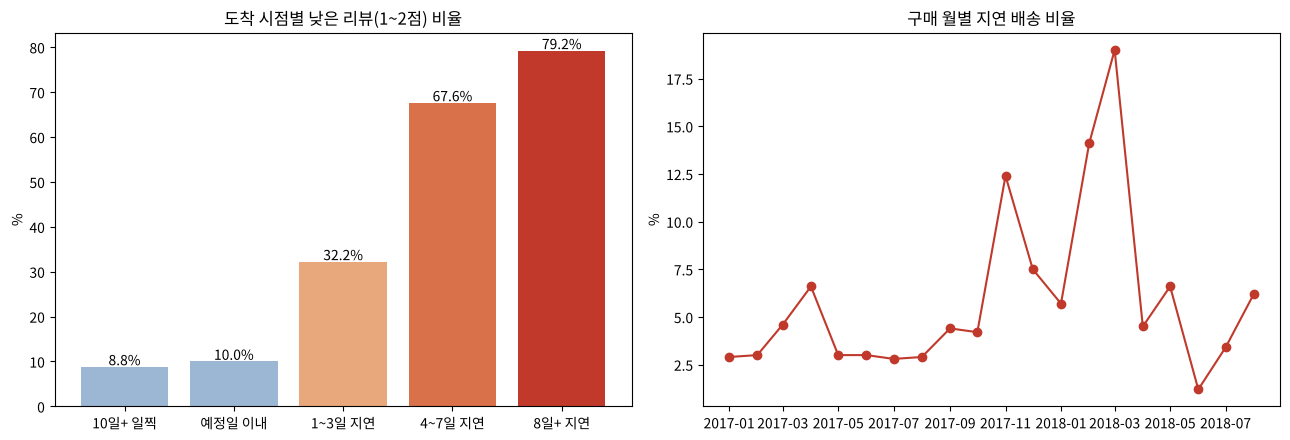

In [35]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

available = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP', 'NanumGothic', 'Malgun Gothic']:
    if name in available:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False

delay = %sql SELECT CASE WHEN delay_days <= -10 THEN '10일+ 일찍' WHEN delay_days <= 0 THEN '예정일 이내' WHEN delay_days <= 3 THEN '1~3일 지연' WHEN delay_days <= 7 THEN '4~7일 지연' ELSE '8일+ 지연' END AS delay_group, MIN(delay_days) AS sort_key, ROUND(100.0 * AVG(CASE WHEN review_score <= 2 THEN 1.0 ELSE 0 END), 1) AS low_review_pct FROM order_base WHERE review_score IS NOT NULL GROUP BY delay_group ORDER BY sort_key
delay = delay.DataFrame()
monthly = %sql SELECT purchase_month, ROUND(100.0 * AVG(is_late), 1) AS late_pct FROM order_base GROUP BY purchase_month ORDER BY purchase_month
monthly = monthly.DataFrame()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars = axes[0].bar(delay['delay_group'], delay['low_review_pct'],
                   color=['#9bb7d4', '#9bb7d4', '#e8a87c', '#d9724b', '#c0392b'])
axes[0].bar_label(bars, fmt='%.1f%%')
axes[0].set_title('도착 시점별 낮은 리뷰(1~2점) 비율')
axes[0].set_ylabel('%')
axes[1].plot(pd.to_datetime(monthly['purchase_month']), monthly['late_pct'], marker='o', color='#c0392b')
axes[1].set_title('구매 월별 지연 배송 비율')
axes[1].set_ylabel('%')
plt.tight_layout()
plt.show()

**6단계 판단**: 배송 지연은 첫 구매 고객의 경험을 확실하게 떨어뜨렸습니다. 재구매에 미친 영향은 이 데이터로 확정할 수 없었지만, 리뷰 점수는 이후 고객의 상품 선택에도 영향을 주는 지표이므로 지연 관리는 우선순위가 높은 과제로 판단했습니다.

## 7. 결론과 제안

### 7-1. 결과 요약

| 질문 | 결과 |
|---|---|
| 고객은 다시 구매하는가 | 실제 재구매율 2.15%, 1년 내 두 번째 구매 3.33%로 대부분 1회 구매에 그쳤습니다. |
| 매출은 어디에 몰려 있는가 | 상위 20% 고객이 매출의 53.5%를 차지했고, 매출의 69.6%가 고액 1회 고객에게서 나왔습니다. |
| 어떤 카테고리가 재구매로 이어졌는가 | 패션 가방, 가구·인테리어, 침구·욕실로 시작한 고객의 재구매율이 높았고, 재구매의 61.9%는 다른 카테고리로 이어졌습니다. |
| 배송 지연의 영향은 | 통제 후에도 낮은 리뷰 확률이 26.3%p 높았습니다. 재구매 감소는 유의하지 않았습니다(p = 0.18). |

### 7-2. 제안

1. **지연 급증 시기의 배송 예정일 관리**: 지연 비율이 12~19%까지 오른 2017-11, 2018-02~03과 같은 시기(블랙프라이데이처럼 미리 알 수 있는 성수기, 또는 2번의 월별 지표로 지연 증가가 감지된 시기)에는 예정일을 보수적으로 안내하거나 배송 여력을 미리 확보하는 것을 제안했습니다. 1~3일 지연만으로도 낮은 리뷰가 3배로 늘었으므로, 예정일을 지키는 것 자체가 핵심이었습니다.
2. **지연 비율을 고객 경험의 선행 지표로 관리**: 분석 기간(2017-01 ~ 2018-02)의 지연 첫 주문 3,671건 중 50%만 제때 배송했어도 낮은 리뷰를 약 480건 줄일 수 있었던 것으로 추정했습니다(6-5). 월별 지연 비율을 대시보드 지표로 두고 기준선(평소 3~6%)을 넘으면 알림을 받는 방식을 제안했습니다.
3. **재구매 실험은 홈 카테고리부터**: 재구매율이 높고 교차 구매가 많았던 가구·인테리어, 침구·욕실 첫 구매 고객을 대상으로 연관 카테고리 추천 실험을 먼저 진행하는 것을 제안했습니다.

### 7-3. 한계

- 관찰 데이터 분석이었으므로 통제하지 못한 요인(판매자 품질, 상품 상태 등)이 결과에 섞였을 수 있습니다. 판매자 단위 변수를 추가하거나 배송 정책 변경 전후를 비교하면 인과 해석을 강화할 수 있습니다.
- 재구매 고객이 2,005명으로 적어 재구매 관련 추정의 신뢰구간이 넓었습니다.
- 리뷰는 배송 완료 후 작성되므로, 리뷰를 남기지 않은 고객(643건)의 경험은 반영되지 않았습니다.

## 8. 후속 실험 설계

6단계에서 배송 지연이 낮은 리뷰를 늘렸다는 점은 확인했지만, 관찰 데이터였으므로 판매자 품질처럼 통제하지 못한 요인이 남아 있었습니다. 또한 재구매에 미친 영향은 재구매 고객 수가 적어 확인하지 못했습니다(p = 0.18). 7단계의 제안을 실제로 적용하기 전에 효과를 검증할 수 있도록 A/B 테스트를 설계했습니다.

### 8-1. 실험 개요

| 항목 | 내용 |
|---|---|
| 가설 | 지연 급증 시기에 배송 예정일을 보수적으로(더 길게) 안내하면, 예정일보다 늦게 도착하는 주문이 줄어 낮은 리뷰(1~2점) 비율이 감소할 것이다 |
| 대조군(A) | 기존 방식으로 배송 예정일 안내 |
| 실험군(B) | 지역·카테고리별 과거 지연 이력을 반영해 예정일을 늘려서 안내 |
| 대상 | 지연 급증 시기의 신규 고객 첫 주문 (지연이 많은 시기여야 예정일 조정의 효과가 드러나기 때문) |
| 배정 단위 | 고객(customer_unique_id) 단위로 50:50 무작위 배정. 같은 고객이 두 그룹을 모두 경험하지 않도록 했습니다. |
| 1차 지표 | 첫 주문의 낮은 리뷰(1~2점) 비율 (실험 성공 여부를 판단하는 기준 지표. 적은 인원과 짧은 기간으로 확인할 수 있어 선택, 8-3 참고) |
| 보조 지표 | 예정일 대비 지연 비율, 180일 내 재구매율 |
| 가드레일 지표 | 구매 전환율, 주문 취소율 (예정일이 길어져 구매를 포기하는 고객이 늘지 않는지 확인) |

가드레일 지표를 둔 이유는, 예정일을 길게 안내하면 지연은 줄어도 상품 상세 화면에서 구매를 포기하는 고객이 늘 수 있기 때문입니다. 리뷰가 좋아져도 전환율이 떨어지면 매출 측면에서는 손해일 수 있으므로 두 지표를 함께 보도록 설계했습니다.

### 8-2. 기준값 확인

실험 대상과 같은 조건(지연 급증 시기인 2017-11, 2018-02, 2018-03의 첫 주문)에서 지연 비율과 낮은 리뷰 비율을 확인했습니다.

In [ ]:
%%sql
# 지연 급증 시기(2017-11, 2018-02, 2018-03)와 그 외 시기의 첫 주문 비교 결과입니다.
WITH first_order AS (
    SELECT *
    FROM (
        SELECT b.*,
               ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchase_ts, order_id) AS rn
        FROM order_base b
    ) t
    WHERE rn = 1
)
SELECT CASE WHEN purchase_month IN (DATE '2017-11-01', DATE '2018-02-01', DATE '2018-03-01')
            THEN '지연 급증 시기' ELSE '그 외 시기' END            AS period,
       COUNT(*)                                                    AS first_orders,
       ROUND(COUNT(*) / COUNT(DISTINCT purchase_month), 0)        AS first_orders_per_month,
       ROUND(100.0 * AVG(is_late), 1)                              AS late_pct,
       ROUND(100.0 * SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END) / COUNT(review_score), 1) AS low_review_pct
FROM first_order
GROUP BY period
ORDER BY period DESC;

Running query in 'duckdb:///olist.duckdb'

period,first_orders,first_orders_per_month,late_pct,low_review_pct
지연 급증 시기,20123,6708.0,15.2,19.0
그 외 시기,72973,4293.0,4.5,11.1


지연 급증 시기의 첫 주문은 지연 비율 15.2%, 낮은 리뷰 비율 19.0%로 그 외 시기(4.5%, 11.1%)보다 크게 높았습니다. 이 시기에 신규 고객의 첫 주문은 월 약 6,700건이었습니다.

**기대 효과 추정**: 실험군(B)에서 원래 늦었을 주문의 절반이 늘어난 예정일 안에 도착하는 것으로 바뀐다고 가정했습니다. 예를 들어 5일로 안내했는데 7일 걸린 주문은 예정일을 8일로 늘리면 제때 도착이 되지만, 10일 걸린 주문은 여전히 늦습니다. 이렇게 일부만 바뀌므로 그 비율을 절반(0.5)으로 가정했습니다.

고객 100명 기준으로 계산하면, 지연 고객 15.2명 중 절반인 7.6명이 제때 도착으로 바뀌고, 이들의 낮은 리뷰 확률이 각각 26.3%p 줄어 약 2명(7.6 × 0.263)이 낮은 리뷰를 덜 줍니다. 즉 낮은 리뷰 비율이 약 2%p(15.2% × 0.5 × 26.3%p) 줄어드는 것으로 추정했습니다.

이 값을 최소 검출 효과로 삼았습니다. 최소 검출 효과는 '실험에서 최소한 이 정도 차이는 놓치지 않고 잡아내도록' 표본 수를 정하는 기준입니다. 0.5가 가정값이므로 8-3에서는 1~3%p 범위를 함께 계산했습니다.

### 8-3. 필요 표본 수와 실험 기간

유의수준 5%, 검정력 80%(실제 효과가 있을 때 이를 잡아낼 확률)라는 일반적인 기준으로 그룹당 필요한 고객 수를 계산했습니다. `months_needed`는 두 그룹 인원을 모두 모으는 데 걸리는 개월 수입니다.

In [37]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

power_analysis = NormalIndPower()
first_orders_per_month = 6700        # 지연 급증 시기 월평균 첫 주문 수 (8-2 결과)

scenarios = [
    ('낮은 리뷰', 0.190, 0.180, '1%p 감소'),
    ('낮은 리뷰', 0.190, 0.170, '2%p 감소 (기대 효과)'),
    ('낮은 리뷰', 0.190, 0.160, '3%p 감소'),
    ('180일 재구매', 0.0201, 0.0161, '6-4에서 관찰된 차이'),
    ('180일 재구매', 0.0201, 0.0221, '10% 증가'),
]

rows = []
for metric, base, target, label in scenarios:
    effect = abs(proportion_effectsize(base, target))
    n_per_group = power_analysis.solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1)
    rows.append({
        'metric': metric,
        'scenario': label,
        'baseline_pct': round(100 * base, 2),
        'target_pct': round(100 * target, 2),
        'n_per_group': int(np.ceil(n_per_group)),
        'months_needed': round(2 * n_per_group / first_orders_per_month, 1),
    })

sample_size = pd.DataFrame(rows)
sample_size

,metric,scenario,baseline_pct,target_pct,n_per_group,months_needed
0,낮은 리뷰,1%p 감소,19.00,18.00,23665,7.1
1,낮은 리뷰,2%p 감소 (기대 효과),19.00,17.00,5789,1.7
2,낮은 리뷰,3%p 감소,19.00,16.00,2514,0.8
3,180일 재구매,6-4에서 관찰된 차이,2.01,1.61,17384,5.2
4,180일 재구매,10% 증가,2.01,2.21,81014,24.2


- **낮은 리뷰**: 기대 효과인 2%p 감소를 확인하려면 그룹당 약 6,000명이 필요했고, 지연 급증 시기 기준 약 2개월이면 모을 수 있었습니다. 효과가 1%p로 작으면 7개월이 걸려 한 번의 급증 시기로는 부족했습니다.
- **180일 재구매**: 재구매율은 2% 안팎으로 매우 낮고 6-4에서 관찰된 차이도 0.4%p(2.01% → 1.61%)로 작아서, 이 차이를 확인하려면 그룹당 약 17,000명이 필요했습니다. 6-4에서 비교한 지연 고객은 3,671명으로 필요한 인원의 약 1/5이었습니다. 실제 차이가 있더라도 확인되기 어려운 조건이었으므로, 6-4에서 재구매 효과가 유의하지 않았던 것은 효과가 없어서라기보다 표본이 부족했기 때문일 가능성이 컸습니다.

| | 낮은 리뷰 | 180일 재구매 |
|---|---|---|
| 그룹당 필요 인원 | 약 6,000명 | 약 17,000명 |
| 인원을 모으는 기간 | 약 2개월 | 약 5개월 |
| 결과를 알 수 있는 시점 | 배송 후 리뷰가 달리면 바로 | 첫 구매 후 180일 뒤 |
| 실험 전체 소요 | 약 2~3개월 | 약 11개월 |

재구매를 1차 지표로 삼으면 인원을 5개월 동안 모은 뒤 다시 180일을 기다려야 해 결론까지 1년 가까이 걸렸습니다. 그래서 적은 인원과 짧은 기간으로 확인할 수 있는 낮은 리뷰를 1차 지표로 정하고, 재구매는 보조 지표로 장기 추적하도록 했습니다.

### 8-4. 분석 절차

실험이 끝난 뒤에는 다음 순서로 분석하도록 정했습니다. 아래 코드는 실제 실험 결과가 아니라, 8-2의 기준값과 8-3의 기대 효과로 만든 **가상 데이터**로 분석 절차를 확인한 것입니다.

1. **배정 비율 확인(SRM 점검)**: 두 그룹 인원이 50:50에서 벗어나면 배정 과정에 문제가 있는 것이므로 결과를 해석하지 않습니다(카이제곱 검정, p < 0.01이면 중단). 이 점검은 결과를 버릴지 정하는 경보 장치이므로, 정상적인 실험을 잘못 중단하지 않도록 일반 기준(0.05)보다 엄격한 0.01을 사용했습니다.
2. **1차 지표 비교**: 두 그룹의 낮은 리뷰 비율 차이를 두 비율 z검정과 95% 신뢰구간으로 확인합니다.
3. **가드레일 확인**: 리뷰가 좋아져도 B그룹의 구매 전환율이 유의하게 떨어졌다면, 늘어난 예정일 때문에 구매를 포기한 고객이 늘어난 것이므로 바로 적용하지 않습니다(8-5의 경우 2).

In [ ]:
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

# 가상 데이터: 그룹당 약 6,000명, 대조군 낮은 리뷰 19%, 실험군 17%로 가정했습니다.
rng = np.random.default_rng(42)
n_total = 12000
group = rng.choice(['A', 'B'], size=n_total)
low_review_sim = np.where(group == 'A', rng.random(n_total) < 0.19, rng.random(n_total) < 0.17).astype(int)
sim = pd.DataFrame({'group': group, 'low_review': low_review_sim})

# 1. 배정 비율 확인
counts = sim['group'].value_counts().sort_index()
srm_p = chisquare(counts).pvalue
print(f'그룹별 인원: A {counts["A"]:,}명, B {counts["B"]:,}명 / SRM 검정 p = {srm_p:.3f}')

# 2. 1차 지표 비교
success = sim.groupby('group')['low_review'].sum().sort_index()
nobs = sim.groupby('group')['low_review'].count().sort_index()
z_stat, p_value = proportions_ztest(success, nobs)
ci_low, ci_high = confint_proportions_2indep(success['B'], nobs['B'], success['A'], nobs['A'])
rate = success / nobs
print(f'낮은 리뷰 비율: A {100*rate["A"]:.1f}%, B {100*rate["B"]:.1f}%')
print(f'차이(B - A): {100*(rate["B"] - rate["A"]):.1f}%p, 95% 신뢰구간 {100*ci_low:.1f} ~ {100*ci_high:.1f}%p, p = {p_value:.4f}')

그룹별 인원: A 6,033명, B 5,967명 / SRM 검정 p = 0.547
낮은 리뷰 비율: A 18.7%, B 16.9%
차이(B - A): -1.8%p, 95% 신뢰구간 -3.1 ~ -0.4%p, p = 0.0120


가상 데이터에서는 두 그룹 인원이 6,033명과 5,967명으로 50:50에 가까웠고 SRM 검정 p = 0.547로 배정에 문제가 없었습니다. 낮은 리뷰 비율은 A 18.7%, B 16.9%로 B가 1.8%p 낮았고, 차이의 95% 신뢰구간(-3.1 ~ -0.4%p)이 모두 0보다 작고 p = 0.012로 유의한 감소로 판정되었습니다. 실제 실험에서도 같은 절차로 판단하도록 정했습니다.

### 8-5. 실험 전 의사결정 기준과 설계의 한계

아래 표는 실험 결과가 아닌, 결과를 본 뒤 해석을 바꾸지 않도록 **실험 시작 전에 미리 정해 둔 판단 기준**입니다.

**용어 정의**
- A그룹: 기존 방식대로 배송 예정일을 안내받은 고객
- B그룹: 지역·카테고리별 과거 지연 이력을 반영해 늘린 예정일을 안내받은 고객
- 유의하다: 두 그룹 차이의 p값이 0.05 미만이고, 차이의 95% 신뢰구간이 0을 포함하지 않는 경우

| 경우 | 판단 기준 | 해석 | 결정 |
|---|---|---|---|
| 0. 그룹 배정 오류 | SRM 검정 p < 0.01 | 고객이 50:50으로 나뉘지 않아 두 그룹 비교 자체를 믿을 수 없음 | 결과를 해석하지 않고, 배정 오류를 수정한 뒤 다시 실험 |
| 1. 리뷰 개선, 구매 영향 없음 | B의 낮은 리뷰 비율이 A보다 유의하게 낮고, B의 구매 전환율은 A보다 유의하게 낮지 않음 | 예정일을 현실적으로 안내하는 것만으로 불만이 줄었고, 긴 예정일 때문에 구매를 포기한 고객도 늘지 않음 | 다음 지연 급증 시기부터 모든 신규 고객의 첫 주문에 늘린 예정일 안내를 적용하고, 낮은 리뷰 비율과 구매 전환율을 월별로 계속 확인 |
| 2. 리뷰 개선, 구매 감소 | B의 낮은 리뷰 비율이 유의하게 낮지만, B의 구매 전환율도 A보다 유의하게 낮음 | 리뷰는 좋아졌지만 긴 예정일을 보고 구매를 포기한 고객이 늘어 매출이 줄 수 있음 | 바로 적용하지 않고, 예정일을 늘리는 폭을 절반으로 줄인 조건으로 다시 실험해 리뷰 개선과 구매 감소 사이의 균형점을 찾음 |
| 3. 리뷰 차이 없음 | 낮은 리뷰 비율 차이의 p값이 0.05 이상(신뢰구간이 0을 포함) | 약속한 날짜를 지켜도 불만이 줄지 않았으므로, 약속이 깨진 것보다 실제로 오래 기다린 것이 불만의 주된 원인일 가능성이 큼 | 예정일 안내 변경은 적용하지 않고, 지연 급증이 예상되는 시기(블랙프라이데이 등 성수기) 전에 배송 인력과 물류 거점을 확보하는 등 실제 배송 기간을 줄이는 방안을 우선 검토. 판매자 품질 등 다른 원인도 남아 있으므로 확정이 아닌 검토 대상으로 둠 |
| 4. 리뷰 악화 | B의 낮은 리뷰 비율이 A보다 유의하게 높음 | 늘어난 예정일 자체가 "배송이 느리다"는 불만을 만든 것으로 해석 | 실험을 중단하고 기존 안내 방식을 유지 |

**설계의 한계**

- **가드레일 지표를 계산하지 못했습니다.** 구매 전환율을 구하려면 상품 화면을 본 고객 수가 필요하지만, Olist 데이터에는 구매한 주문 기록만 있고 방문·조회 기록이 없었습니다. 구매 전환율과 주문 취소율은 실제 실험 시 서비스 로그로 측정해야 합니다.
- **기대 효과(2%p)는 가정에 기반했습니다.** 지연 주문의 절반이 예정일 안 도착으로 바뀐다는 가정을 사용했으므로 실제 효과는 다를 수 있습니다. 이를 고려해 8-3에서 1~3%p 범위의 표본 수를 함께 계산했습니다.
- **26.3%p 효과가 그대로 나타나지 않을 수 있습니다.** 6-4의 효과는 실제로 늦게 도착한 주문과 제때 도착한 주문을 비교한 값이었습니다. 이 실험은 실제 도착 시점은 그대로 두고 안내만 바꾸므로, 고객이 지연은 아니어도 배송이 느리다고 느껴 불만이 남을 수 있습니다.
- **실험 기간이 제한됩니다.** 지연 급증 시기는 1년에 몇 달뿐이므로, 필요한 기간(약 2개월)을 한 번의 급증 시기 안에 확보하지 못하면 다음 시기까지 실험을 이어 가야 합니다.
- **8-4는 가상 데이터입니다.** 8-4의 수치는 분석 절차를 확인하기 위해 만든 값이며 실제 실험 결과가 아닙니다.

**8단계 판단**: 관찰 분석으로 찾은 효과를 실험으로 검증할 수 있도록 설계했습니다. 재구매는 그룹당 약 1만 7천 명이 필요하고 결과를 보기까지 180일을 더 기다려야 해서 실험 기간이 1년 가까이 걸렸습니다. 반면 낮은 리뷰는 그룹당 약 6천 명, 2개월 정도면 확인할 수 있어 1차 지표로 정하고, 재구매는 보조 지표로 장기 추적하도록 했습니다. 이 계산은 6-4에서 재구매 효과가 유의하지 않았던 이유(표본 부족)를 설명하는 근거도 되었습니다.